In [5]:
# Setup and Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [6]:
# Mount Google Drive and Set Paths
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

Mounted at /content/drive


In [9]:
# Load Fulvestrant Subset

base_dir = Path("/content/drive/My Drive/gdsc-drug-response")
fulvestrant_path = base_dir / "processed" / "gdsc_fulvestrant_ln_ic50.csv"

df = pd.read_csv(fulvestrant_path)
df.head()

df.info()
print("Shape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1680 entries, 0 to 1679
Data columns (total 19 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   COSMIC_ID                                1680 non-null   int64  
 1   CELL_LINE_NAME                           1680 non-null   object 
 2   TCGA_DESC                                1674 non-null   object 
 3   DRUG_ID                                  1680 non-null   int64  
 4   DRUG_NAME                                1680 non-null   object 
 5   LN_IC50                                  1680 non-null   float64
 6   AUC                                      1680 non-null   float64
 7   Z_SCORE                                  1680 non-null   float64
 8   GDSC Tissue descriptor 1                 1615 non-null   object 
 9   GDSC Tissue descriptor 2                 1615 non-null   object 
 10  Cancer Type (matching TCGA label)        1321 no

In [10]:
# Basic Checks and Summary Stats

response_col = "LN_IC50"
drug_col     = "DRUG_NAME"    # or whatever you used
cell_col     = "CELL_LINE_NAME"    # adjust if needed

df[[drug_col, cell_col, response_col]].head()

df[response_col].describe()

df[drug_col].value_counts()

,count
DRUG_NAME,
Fulvestrant,1680


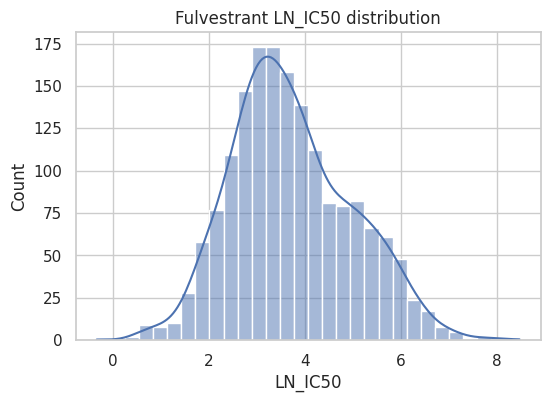

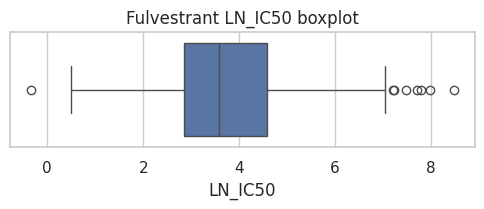

In [11]:
# Explore LN_IC50 Distribution

plt.figure(figsize=(6,4))
sns.histplot(df[response_col], bins=30, kde=True)
plt.title("Fulvestrant LN_IC50 distribution")
plt.xlabel("LN_IC50")
plt.ylabel("Count")
plt.show()


plt.figure(figsize=(6,1.5))
sns.boxplot(x=df[response_col])
plt.title("Fulvestrant LN_IC50 boxplot")
plt.xlabel("LN_IC50")
plt.show()

Feature Overview

In [12]:
# Define which columns are not features:

non_feature_cols = [drug_col, cell_col, response_col]  # add any others like tissue type
feature_cols = [c for c in df.columns if c not in non_feature_cols]

len(feature_cols), feature_cols[:10]

(16,
 ['COSMIC_ID',
  'TCGA_DESC',
  'DRUG_ID',
  'AUC',
  'Z_SCORE',
  'GDSC Tissue descriptor 1',
  'GDSC Tissue descriptor 2',
  'Cancer Type (matching TCGA label)',
  'Microsatellite instability Status (MSI)',
  'Screen Medium'])

In [13]:
# Check missingness across features:

missing_frac = df[feature_cols].isna().mean().sort_values(ascending=False)
missing_frac.head(20)

,0
Cancer Type (matching TCGA label),0.213690
Microsatellite instability Status (MSI),0.050000
GDSC Tissue descriptor 2,0.038690
GDSC Tissue descriptor 1,0.038690
CNA,0.038690
Growth Properties,0.038690
Screen Medium,0.038690
Gene Expression,0.038690
Methylation,0.038690
TCGA_DESC,0.003571


In [14]:
# Look at basic stats for features:

df[feature_cols].describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
COSMIC_ID,1680.0,9.908096e+05,220286.863397,683667.000000,906801.000000,909716.500000,1.240141e+06,1.789883e+06
DRUG_ID,1680.0,1.462900e+03,304.770863,1200.000000,1200.000000,1200.000000,1.816000e+03,1.816000e+03
AUC,1680.0,9.710035e-01,0.020702,0.796471,0.964634,0.977469,9.838525e-01,9.968600e-01
Z_SCORE,1680.0,2.976190e-09,0.999702,-3.792624,-0.661386,0.004393,6.713925e-01,3.769942e+00


In [16]:
# Save a “ready for modeling” version (optional)

# Example: drop features with >80% missing
keep_feats = missing_frac[missing_frac <= 0.8].index.tolist()
df_clean = df[non_feature_cols + keep_feats].copy()

clean_model_path = base_dir / "processed" / "gdsc_fulvestrant_ln_ic50_modelready.csv"
df_clean.to_csv(clean_model_path, index=False)
clean_model_path

PosixPath('/content/drive/My Drive/gdsc-drug-response/processed/gdsc_fulvestrant_ln_ic50_modelready.csv')